# Exercice 2 — Entraîner un agent avec une table de décision (Q-table)

**Objectif** : implémenter de zéro l'algorithme **Q-Learning** sur **FrozenLake-v1**.

L'agent part de `S`, doit atteindre le cadeau `G` en marchant sur la glace `F` sans tomber dans un trou `H`.
La glace est **glissante** (`is_slippery=True`) : l'action choisie n'est exécutée qu'une fois sur trois,
sinon l'agent glisse perpendiculairement. Récompense : **1** en atteignant `G`, **0** sinon.

```
S F F F
F H F H
F F F H
H F F G
```

Pourquoi FrozenLake ? **16 états discrets × 4 actions** : tout tient dans un tableau 16×4, idéal pour comprendre le Q-learning.

In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

## Étape 1 — Créer l'environnement et initialiser la Q-table

Les dimensions sont lues dynamiquement : `observation_space.n` lignes (états), `action_space.n` colonnes (actions).

In [2]:
env = gym.make("FrozenLake-v1", is_slippery=True)

n_states = env.observation_space.n
n_actions = env.action_space.n
print("Espace d'observation :", env.observation_space, "->", n_states, "états")
print("Espace d'action      :", env.action_space, "->", n_actions, "actions (0=←, 1=↓, 2=→, 3=↑)")

q_table = np.zeros((n_states, n_actions))
print("Q-table :", q_table.shape)
q_table

Espace d'observation : Discrete(16) -> 16 états
Espace d'action      : Discrete(4) -> 4 actions (0=←, 1=↓, 2=→, 3=↑)
Q-table : (16, 4)


array([[0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.]])

## Étape 2 — Boucle d'entraînement (epsilon-greedy + équation de Bellman)

À chaque pas :
1. **Exploration vs exploitation** : tirage `u ~ U(0,1)` ; si `u < ε` → action aléatoire, sinon `argmax Q[s, :]`.
2. **Mise à jour de Bellman** sur la paire `(state, action)` utilisée :

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\big[r + \gamma \max_{a'} Q(s',a') - Q(s,a)\big]$$

3. En fin d'épisode, **ε décroît** (décroissance exponentielle) : l'agent explore de moins en moins.

Si l'état suivant est terminal (trou ou but), il n'y a pas de futur : `max Q(s', ·)` vaut 0
(c'est déjà le cas ici puisque les lignes des états terminaux ne sont jamais mises à jour, mais on le rend explicite).

In [3]:
# Hyperparamètres
N_EPISODES      = 20_000
LEARNING_RATE   = 0.1     # α
DISCOUNT_FACTOR = 0.99    # γ : on valorise fortement le futur (récompense uniquement à la fin)
EPSILON_MAX     = 1.0
EPSILON_MIN     = 0.01
EPSILON_DECAY   = 0.0005  # ε = ε_min + (ε_max - ε_min) * exp(-decay * épisode)
MAX_STEPS       = 100

epsilon = EPSILON_MAX
train_rewards, epsilons = [], []

for episode in range(N_EPISODES):
    state, _ = env.reset(seed=SEED + episode)
    total_reward = 0.0

    for _ in range(MAX_STEPS):
        # 1) epsilon-greedy
        if rng.random() < epsilon:
            action = int(rng.integers(n_actions))       # explorer
        else:
            action = int(np.argmax(q_table[state, :]))  # exploiter

        new_state, reward, terminated, truncated, _ = env.step(action)

        # 2) Bellman : la cible utilise new_state ; la mise à jour porte sur (state, action)
        max_q_futur = 0.0 if terminated else np.max(q_table[new_state, :])
        ancienne_valeur = q_table[state, action]
        q_table[state, action] = ancienne_valeur + LEARNING_RATE * (
            reward + DISCOUNT_FACTOR * max_q_futur - ancienne_valeur
        )

        state = new_state
        total_reward += reward
        if terminated or truncated:
            break

    # 3) décroissance d'epsilon en fin d'épisode
    epsilon = EPSILON_MIN + (EPSILON_MAX - EPSILON_MIN) * np.exp(-EPSILON_DECAY * episode)
    train_rewards.append(total_reward)
    epsilons.append(epsilon)

    if (episode + 1) % 2000 == 0:
        print(f"Épisode {episode + 1:6d} | ε = {epsilon:.3f} | "
              f"taux de réussite (1000 derniers) = {np.mean(train_rewards[-1000:]):.1%}")

Épisode   2000 | ε = 0.374 | taux de réussite (1000 derniers) = 6.5%


Épisode   4000 | ε = 0.144 | taux de réussite (1000 derniers) = 24.4%


Épisode   6000 | ε = 0.059 | taux de réussite (1000 derniers) = 45.6%


Épisode   8000 | ε = 0.028 | taux de réussite (1000 derniers) = 61.0%


Épisode  10000 | ε = 0.017 | taux de réussite (1000 derniers) = 64.9%


Épisode  12000 | ε = 0.012 | taux de réussite (1000 derniers) = 66.5%


Épisode  14000 | ε = 0.011 | taux de réussite (1000 derniers) = 65.0%


Épisode  16000 | ε = 0.010 | taux de réussite (1000 derniers) = 70.0%


Épisode  18000 | ε = 0.010 | taux de réussite (1000 derniers) = 68.8%


Épisode  20000 | ε = 0.010 | taux de réussite (1000 derniers) = 68.8%


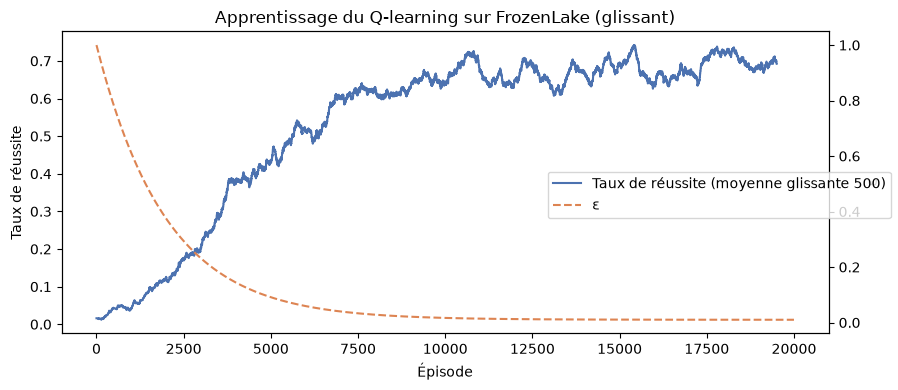

In [4]:
window = 500
moving_success = np.convolve(train_rewards, np.ones(window) / window, mode="valid")

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(moving_success, color="#4C72B0", label=f"Taux de réussite (moyenne glissante {window})")
ax1.set_xlabel("Épisode"); ax1.set_ylabel("Taux de réussite")
ax2 = ax1.twinx()
ax2.plot(epsilons, color="#DD8452", ls="--", label="ε")
ax2.set_ylabel("ε")
fig.legend(loc="center right"); ax1.set_title("Apprentissage du Q-learning sur FrozenLake (glissant)")
fig.tight_layout(); plt.show()

### Q-table apprise et politique gloutonne associée

In [5]:
np.set_printoptions(precision=3, suppress=True)
print(q_table)

arrows = np.array(["←", "↓", "→", "↑"])
desc = env.unwrapped.desc.astype(str)
policy = arrows[np.argmax(q_table, axis=1)].reshape(desc.shape)
# On n'affiche une flèche que sur les cases où l'agent peut se trouver (glace / départ)
grid = np.where(np.isin(desc, ["H", "G"]), desc, policy)
print("\nPolitique (H = trou, G = but) :")
print("\n".join(" ".join(row) for row in grid))

[[0.531 0.522 0.516 0.505]
 [0.369 0.236 0.248 0.514]
 [0.418 0.407 0.411 0.482]
 [0.356 0.287 0.326 0.467]
 [0.544 0.351 0.508 0.274]
 [0.    0.    0.    0.   ]
 [0.281 0.213 0.371 0.192]
 [0.    0.    0.    0.   ]
 [0.358 0.409 0.407 0.583]
 [0.467 0.623 0.523 0.46 ]
 [0.579 0.425 0.448 0.411]
 [0.    0.    0.    0.   ]
 [0.    0.    0.    0.   ]
 [0.431 0.522 0.708 0.624]
 [0.731 0.821 0.765 0.763]
 [0.    0.    0.    0.   ]]

Politique (H = trou, G = but) :
← ↑ ↑ ↑
← H → H
↑ ↓ ← H
H → ↓ G


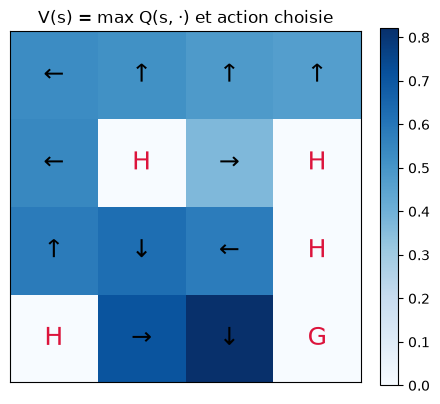

In [6]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
v = q_table.max(axis=1).reshape(desc.shape)
im = ax.imshow(v, cmap="Blues")
for (i, j), cell in np.ndenumerate(grid):
    ax.text(j, i, cell, ha="center", va="center", fontsize=18,
            color="crimson" if cell in ("H", "G") else "black")
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("V(s) = max Q(s, ·) et action choisie")
fig.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

## Étape 3 — Évaluation (100 épisodes, sans exploration)

Plus d'epsilon : l'agent choisit **toujours** `argmax Q[s, :]` et **la Q-table n'est plus modifiée**.

In [7]:
N_EVAL = 100
total_wins = 0

for episode in range(N_EVAL):
    state, _ = env.reset(seed=10_000 + episode)   # graines différentes de l'entraînement
    terminated = truncated = False
    reward = 0.0
    while not (terminated or truncated):
        action = int(np.argmax(q_table[state, :]))
        state, reward, terminated, truncated, _ = env.step(action)
    if reward == 1.0:
        total_wins += 1

env.close()
print(f"Taux de réussite sur {N_EVAL} épisodes : {total_wins / N_EVAL:.0%}")

Taux de réussite sur 100 épisodes : 66%


## Aperçu visuel

**Animation de l'agent entraîné** (politique gloutonne). On montre ici le premier épisode réussi parmi
quelques graines : c'est une illustration, pas une mesure (le taux de réussite réel est celui de l'évaluation ci-dessus).

Graine 20001 : réussite en 73 pas


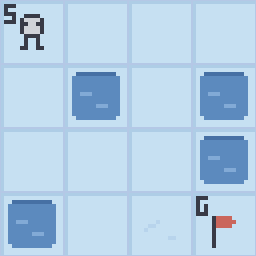

In [8]:
from rl_viz import rollout, save_gif, surface_3d

env_vis = gym.make("FrozenLake-v1", is_slippery=True, render_mode="rgb_array")
greedy = lambda s: int(np.argmax(q_table[s, :]))

for seed in range(50):
    total, states, frames = rollout(env_vis, greedy, seed=20_000 + seed, max_steps=100, render=True)
    if total == 1.0:
        break
env_vis.close()
print(f"Graine {20_000 + seed} : {'réussite' if total == 1.0 else 'échec'} en {len(states) - 1} pas")
save_gif(frames, "ex2_frozenlake_agent.gif", fps=8, width=256)

**Paysage de valeur en 3D** : hauteur = $V(s) = \max_a Q(s, a)$ sur la grille 4×4, couleur = action gloutonne.
La valeur grimpe en approchant du but (coin bas-droit) et s'effondre sur les trous (valeur 0).

In [9]:
v_grid = q_table.max(axis=1).reshape(desc.shape)
a_grid = np.argmax(q_table, axis=1).reshape(desc.shape).astype(float)
a_grid[np.isin(desc, ["H", "G"])] = np.nan          # pas d'action sur les cases terminales
surface_3d(v_grid, "ex2_valeurs_3d", "FrozenLake — V(s) apprise (couleur : action gloutonne 0=← 1=↓ 2=→ 3=↑)",
           x=np.arange(4), y=np.arange(4), labels=("colonne", "ligne", "V(s)"),
           color=a_grid, colorscale="Turbo", colorbar_title="action")

## Conclusion

- Partant d'une table de zéros, l'agent apprend uniquement grâce à une récompense **rare** (1 seule case gratifiante).
- Sur la version **glissante**, on obtient **66 %** de réussite en évaluation (≈ 70 % en fin d'entraînement), proche de l'optimum théorique (~74 %) : même la politique
  parfaite tombe parfois à cause de l'aléa du sol. La politique apprise est « prudente » : elle pousse souvent
  vers les murs pour ne jamais risquer de glisser dans un trou.
- **Limite** : une Q-table exige un nombre fini et petit d'états. CartPole a des états continus → on remplace
  la table par un réseau de neurones : le **DQN** (exercice 3).